In [1]:
# 0. Setup and load the Iris dataset
# If needed, install packages in a notebook cell with:
# %pip install pandas numpy matplotlib seaborn scikit-learn scipy

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score
)
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = "iris.csv"
if not os.path.exists(DATA_PATH) and os.path.exists("/mnt/data/iris.csv"):
    DATA_PATH = "/mnt/data/iris.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())

# This notebook expects four numeric measurement columns and one species/label column.
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
target_col = "species"

# If your column names differ, edit feature_cols and target_col above.
X = df[feature_cols].copy()
y = df[target_col].astype(str).copy()

print("\nSpecies counts:")
print(y.value_counts())


Dataset shape: (150, 5)

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Column names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


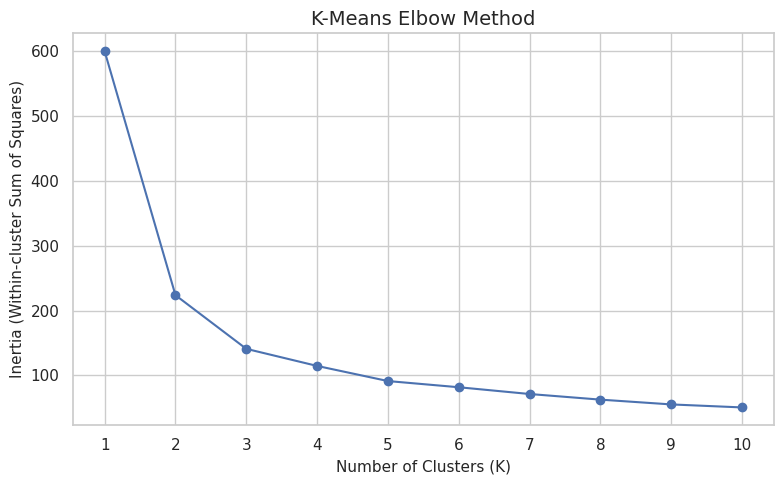

Cluster counts:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64
Silhouette score: 0.4590


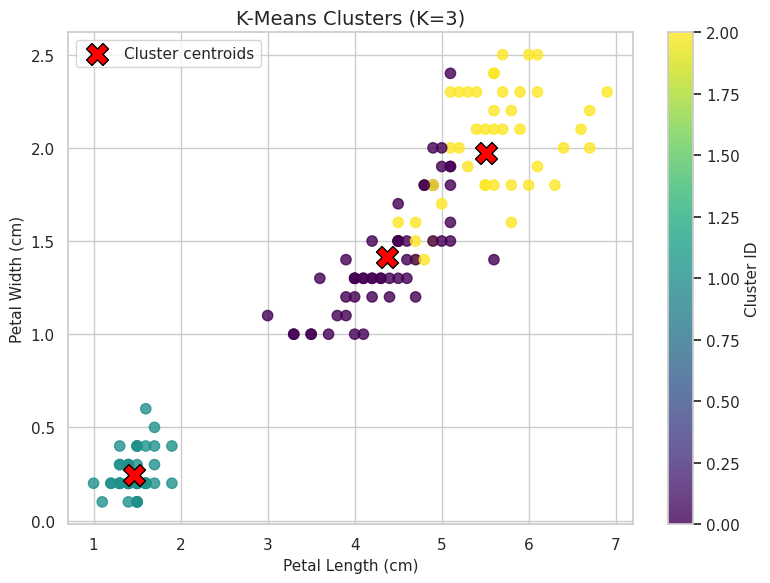


First 10 cluster assignments:


,sepal_length,sepal_width,petal_length,petal_width,species,Cluster
0,5.1,3.5,1.4,0.2,setosa,1
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,1
3,4.6,3.1,1.5,0.2,setosa,1
4,5.0,3.6,1.4,0.2,setosa,1
5,5.4,3.9,1.7,0.4,setosa,1
6,4.6,3.4,1.4,0.3,setosa,1
7,5.0,3.4,1.5,0.2,setosa,1
8,4.4,2.9,1.4,0.2,setosa,1
9,4.9,3.1,1.5,0.1,setosa,1


In [7]:
# 6. K-Means
X_cluster = df[feature_cols]
scaler_km = StandardScaler()
X_scaled = scaler_km.fit_transform(X_cluster)

# Elbow method
inertias = []
k_range = range(1, 11)
for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_test.fit(X_scaled)
    inertias.append(km_test.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker="o")
plt.xticks(list(k_range))
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-cluster Sum of Squares)")
plt.title("K-Means Elbow Method")
plt.tight_layout()
plt.show()

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_ids = kmeans.fit_predict(X_scaled)
df_km = df.copy()
df_km["Cluster"] = cluster_ids
print("Cluster counts:")
print(df_km["Cluster"].value_counts().sort_index())
print(f"Silhouette score: {silhouette_score(X_scaled, cluster_ids):.4f}")

# Plot cluster membership in petal-length/petal-width space
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df_km["petal_length"], df_km["petal_width"],
                      c=cluster_ids, cmap="viridis", s=55, alpha=0.8)
centers_original = scaler_km.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers_original[:, 2], centers_original[:, 3],
            marker="X", s=250, c="red", edgecolor="black", label="Cluster centroids")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("K-Means Clusters (K=3)")
plt.legend()
plt.colorbar(scatter, label="Cluster ID")
plt.tight_layout()
plt.show()

print("\nFirst 10 cluster assignments:")
display(df_km[feature_cols + ["species", "Cluster"]].head(10))
